# Predicting Low-Conversion Job Postings

**UC Berkeley Data 144 — collaborative machine-learning case study**  
**Contributors:** Elise Chang, Mischa Mikami, Sean Tai

**Research question:** Can structured job-posting attributes and text predict whether a LinkedIn job posting will fall into the bottom quartile of application-to-view conversion?

The project joins posting and company information, engineers textual and structured features, and compares four classifiers. The outputs shown below are retained from the original Deepnote execution; this export **has not been re-executed** after packaging.

**Data:** [LinkedIn Job Postings (2023–2024), Arsh Koneru et al., Kaggle](https://www.kaggle.com/datasets/arshkon/linkedin-job-postings). Download the three required CSV files into `data/` as described in the [repository README](README.md) before running the notebook.


## Setup

From the repository root, install dependencies with `pip install -r requirements.txt`. This notebook expects `data/postings.csv`, `data/companies.csv`, and `data/employee_counts.csv`. The dataset files are not included in this repository.


In [ ]:
import pandas as pd
import numpy as np
import re

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn import tree
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy import sparse
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression


In [ ]:
from pathlib import Path

DATA_DIR = Path('data')
required_files = ['postings.csv', 'companies.csv', 'employee_counts.csv']
missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Missing dataset files in {DATA_DIR}/: {', '.join(missing_files)}. "
        "See the repository README for the Kaggle data source and setup."
    )

job_postings = pd.read_csv(DATA_DIR / 'postings.csv')
companies = pd.read_csv(DATA_DIR / 'companies.csv')
employee_counts = pd.read_csv(DATA_DIR / 'employee_counts.csv')

## Data loading and joins

The original dataset contains 123,849 job postings before filtering for usable conversion labels.


In [ ]:
compDf = companies[["company_id", "name", "company_size", "state", "country", "city"]]
employee_counts_sorted = employee_counts.sort_values("time_recorded")
employee_latest = (employee_counts_sorted.groupby("company_id", as_index=False).tail(1).drop(columns=["time_recorded"]))
jobs = job_postings.merge(compDf, on="company_id", how="left").merge(employee_latest, on="company_id", how="left")
jobs.head()

In [ ]:
print(f'jobs dataset: {len(jobs)}')

over_50_nan = jobs.loc[:, jobs.isna().sum() > len(jobs)*0.5]
over_50_nan.isna().sum().sort_values(ascending=False)

jobs dataset: 123849


closed_time          122776
skills_desc          121410
med_salary           117569
remote_allowed       108603
applies              100529
min_salary            94056
max_salary            94056
pay_period            87776
currency              87776
compensation_type     87776
normalized_salary     87776
dtype: int64

## Target definition

Conversion is applications divided by views. After excluding missing/invalid target metrics and the top 1% of conversion-rate outliers, the bottom quartile is labeled **low conversion** (positive class). This threshold was computed on the full filtered dataset before the train/test split; a future revision should learn the threshold only from the training set.


In [ ]:
RANDOM_STATE = 42

df = jobs.copy()

df = df[(df["applies"].notna()) & (df["views"].notna())]
df = df[df["views"] > 0]

df["conversion_rate"] = df["applies"] / df["views"]

# Drop insane outliers on conversion (> 99th percentile)
upper_cap = df["conversion_rate"].quantile(0.99)
df = df[df["conversion_rate"] <= upper_cap]

# Label: 1 = low-conversion, 0 = normal
low_q = df["conversion_rate"].quantile(0.25)
df["low_conversion"] = (df["conversion_rate"] <= low_q).astype(int)

print(df["low_conversion"].value_counts(normalize=True))


low_conversion
0    0.746762
1    0.253238
Name: proportion, dtype: float64


## Feature engineering and preprocessing

Features include posting text, salary and company attributes, one-hot categorical features, missingness indicators, and description-length indicators. Numeric imputation is learned from the training split.


In [ ]:
model_df = df.copy()

# salary features, usually min & max or med salary (one or the other, not both) --> so if ALL values across min/max/med are NAN then consider "missing salary"
model_df["salary_missing"] = model_df[["min_salary", "max_salary", "med_salary"]].isna().all(axis=1).astype(int)

model_df["remote_missing"] = model_df["remote_allowed"].isna().astype(int)
model_df["posting_domain_missing"] = model_df["posting_domain"].isna().astype(int)
model_df["skills_missing"] = model_df["skills_desc"].isna().astype(int)

# format text for logistic regression
model_df["skills_desc"] = model_df["skills_desc"].fillna("")
model_df["title"] = model_df["title"].fillna("")
model_df["description"] = model_df["description"].fillna("")
model_df["text"] = (model_df["title"] + " \n " + model_df["description"] + " \n " + model_df["skills_desc"])

# Simple text feats for trees!
model_df['description_word_count'] = model_df['description'].apply(lambda x: len(x.split()))
model_df['avg_sentence_length'] = model_df['description'].apply(lambda x: np.mean([len(s.split()) for s in re.split(r'[.!?]', x) if len(s.split()) > 0]) if len(x) > 0 else 0)

large_cities = ["New York", "Los Angeles", "Chicago", "Houston", "San Francisco"]
model_df['in_large_city'] = model_df['city'].isin(large_cities).astype(int)
# categorical imputation via filling NA w/ missing
cats_to_fill = [
    "pay_period", "formatted_work_type", "application_type",
    "formatted_experience_level", "currency", "compensation_type",
    "work_type", "remote_allowed", "posting_domain"
]

for c in cats_to_fill:
    model_df[c] = model_df[c].fillna("missing")

for col in ["employee_count", "follower_count", "company_size"]:
    model_df[col + "_missing"] = model_df[col].isna().astype(int)


In [ ]:
drop_cols = [
    "low_conversion","conversion_rate","applies","views", # target features
    "job_id","company_id","job_posting_url","application_url", # irrelevant
    "closed_time","company_name","name","zip_code","fips", "normalized_salary", "posting_domain", "work_type", # irrelevant (popularity of company is encoded in follower count)
    "skills_desc", "title", "description", #included in text feature
    "currency"
]

X = model_df.drop(columns=drop_cols)
y = model_df["low_conversion"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X.isna().sum()

In [ ]:
model_df["company_size_missing"].sum()

1911

In [ ]:
# 1) Numeric columns
numeric_cols = [
    "min_salary", "med_salary", "max_salary",
    "company_size", "employee_count", "follower_count",
    "description_word_count",
    "salary_missing", "remote_missing", "posting_domain_missing","skills_missing", 
    "employee_count_missing", 
    "follower_count_missing",
    "company_size_missing", "in_large_city"
]

# 2) Categorical columns for ohe
categorical_cols = [
    "remote_allowed",
    "pay_period",
    "formatted_work_type",
    "formatted_experience_level",
    "application_type",
    "compensation_type",
]


In [ ]:
# Compute medians on TRAIN, then fill train & test
num_medians = X_train[numeric_cols].median()
X_train[numeric_cols] = X_train[numeric_cols].fillna(num_medians)
X_test[numeric_cols] = X_test[numeric_cols].fillna(num_medians)

In [ ]:
# OHE
X_train = pd.get_dummies(X_train, columns=categorical_cols)
X_test = pd.get_dummies(X_test, columns=categorical_cols)

# we handle text separately for LogReg+TFIDF
X_train_text = X_train
X_test_text = X_test

# align
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)


In [ ]:
X_train

## Model comparison: structured features only

The tree models below use selected numeric/encoded structured features and omit full job-description TF-IDF text. Accordingly, results are not a controlled algorithm-only comparison with the text-enabled logistic regression.


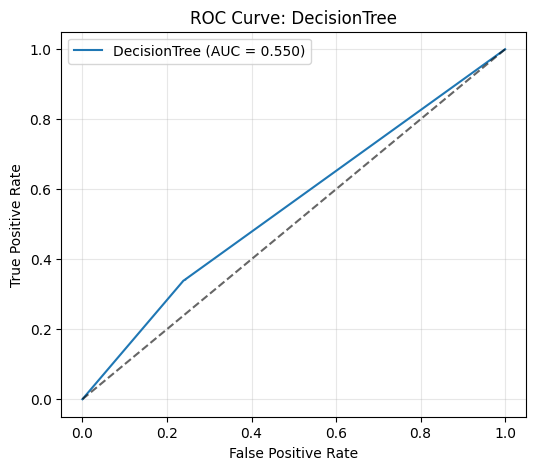

DecisionTree ROC AUC: 0.550
              precision    recall  f1-score   support

           0       0.77      0.76      0.77      3448
           1       0.32      0.34      0.33      1169

    accuracy                           0.65      4617
   macro avg       0.55      0.55      0.55      4617
weighted avg       0.66      0.65      0.66      4617

Confusion matrix:
 [[2624  824]
 [ 773  396]]
------------------------------------------------------------


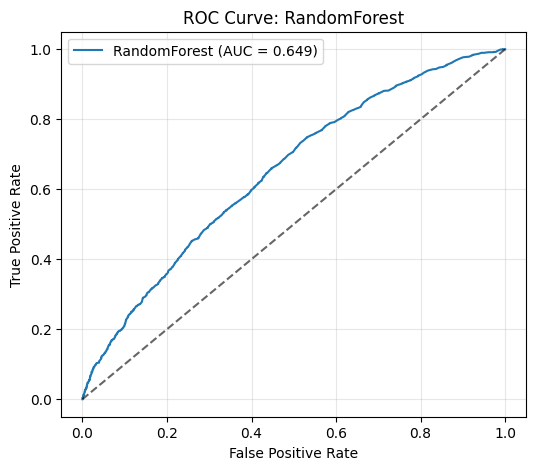

RandomForest ROC AUC: 0.649
              precision    recall  f1-score   support

           0       0.76      0.94      0.84      3448
           1       0.46      0.14      0.22      1169

    accuracy                           0.74      4617
   macro avg       0.61      0.54      0.53      4617
weighted avg       0.69      0.74      0.69      4617

Confusion matrix:
 [[3250  198]
 [1003  166]]
------------------------------------------------------------


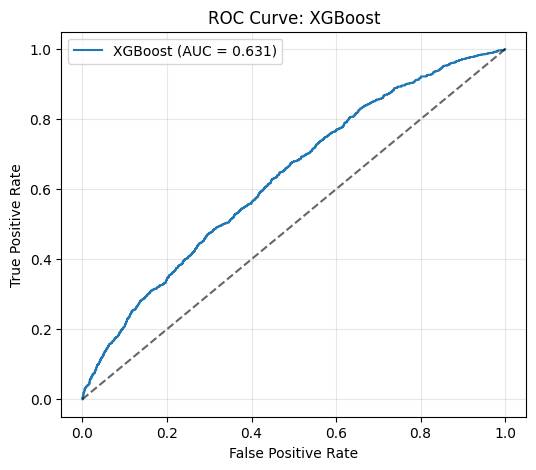

XGBoost ROC AUC: 0.631
              precision    recall  f1-score   support

           0       0.78      0.78      0.78      3448
           1       0.36      0.37      0.37      1169

    accuracy                           0.68      4617
   macro avg       0.57      0.57      0.57      4617
weighted avg       0.68      0.68      0.68      4617

Confusion matrix:
 [[2693  755]
 [ 738  431]]
------------------------------------------------------------


In [ ]:
def evaluate_model(clf, Xtr, ytr, Xte, yte, name="model"):
    clf.fit(Xtr, ytr)
    y_prob = clf.predict_proba(Xte)[:, 1]
    auc = roc_auc_score(yte, y_prob)
    y_pred = clf.predict(Xte)

    fpr, tpr, thresholds = roc_curve(yte, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=0.6)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve: {name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print(f"{name} ROC AUC: {auc:.3f}")
    print(classification_report(yte, y_pred))
    print("Confusion matrix:\n", confusion_matrix(yte, y_pred))
    print("-"*60)
    return auc

# Select only numeric/boolean columns for tree models
X_train_tree = X_train.select_dtypes(exclude=['object'])
X_test_tree = X_test.select_dtypes(exclude=['object'])

# Convert bool features to int for XGBoost compatibility
for col in X_train_tree.select_dtypes(include=['bool']).columns:
    X_train_tree[col] = X_train_tree[col].astype(int)
    X_test_tree[col] = X_test_tree[col].astype(int)

tree = DecisionTreeClassifier(
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)
tree_score = evaluate_model(tree, X_train_tree, y_train, X_test_tree, y_test, name="DecisionTree")

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight={0:1, 1:3},
    # min_samples_split=3,
    # max_depth=25
)
rf_score = evaluate_model(rf, X_train_tree, y_train, X_test_tree, y_test, name="RandomForest")

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=ratio,
    n_estimators=500,
    max_depth=6,
)
xgb_score = evaluate_model(xgb, X_train_tree, y_train, X_test_tree, y_test, name="XGBoost")

In [ ]:
X_train_tree

## Logistic regression with TF-IDF text features

Text is vectorized using unigram/bigram TF-IDF; structured features are scaled and concatenated. The original run generated a convergence warning for the `saga` optimizer, so coefficients and performance should be regarded as preliminary.


/root/venv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


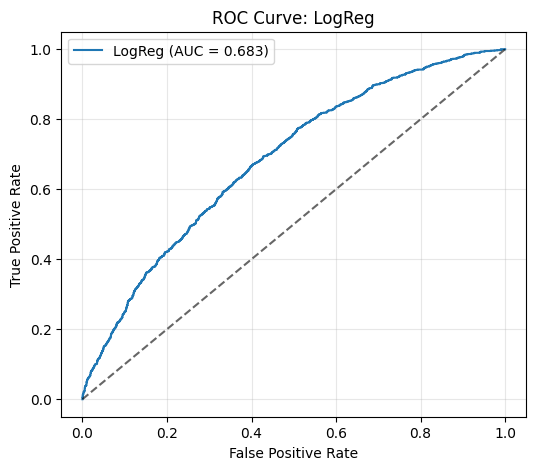

LogReg ROC AUC: 0.683
              precision    recall  f1-score   support

           0       0.84      0.62      0.71      3448
           1       0.36      0.64      0.46      1169

    accuracy                           0.63      4617
   macro avg       0.60      0.63      0.59      4617
weighted avg       0.72      0.63      0.65      4617

Confusion matrix:
 [[2139 1309]
 [ 420  749]]
------------------------------------------------------------


In [ ]:
text_feature = "text"

# Extract text columns
text_train = X_train[text_feature].fillna("")
text_test = X_test[text_feature].fillna("")

tfidf = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2),
    min_df=5
)
X_train_text_features = tfidf.fit_transform(text_train)
X_test_text_features = tfidf.transform(text_test)

# numerics
X_train_struct = X_train.select_dtypes(exclude=['object'])
X_test_struct = X_test.select_dtypes(exclude=['object'])
X_train_struct = X_train_struct.astype(float)
X_test_struct = X_test_struct.astype(float)

# scale the numerics features to help logistic regression
scaler = StandardScaler()
X_train_struct_scaled = scaler.fit_transform(X_train_struct)
X_test_struct_scaled = scaler.transform(X_test_struct)

# Combine text (sparse) + SCALED numeric (dense)
X_train_full = sparse.hstack([X_train_text_features, sparse.csr_matrix(X_train_struct_scaled)])
X_test_full = sparse.hstack([X_test_text_features, sparse.csr_matrix(X_test_struct_scaled)])

logreg = LogisticRegression(
    max_iter=1000,
    solver="saga",
    class_weight={0:1, 1:3}
)

logreg_score = evaluate_model(logreg, X_train_full, y_train, X_test_full, y_test, name="LogReg")

In [ ]:
print("Decision Tree Score:", tree_score)
print("Random Forest Score:", rf_score)
print("XGBoost Score:", xgb_score)
print("LogReg Score:", logreg_score)

Decision Tree Score: 0.5497857450495099
Random Forest Score: 0.6486783228372557
XGBoost Score: 0.6314664754018644
LogReg Score: 0.6831321612658012


## Exploratory coefficient analysis

Coefficients describe associations within the fitted model, **not causal effects** of changing a posting. Positive coefficients increase the modeled log-odds of being low-conversion; negative coefficients decrease them.


In [ ]:
text_feature_names = tfidf.get_feature_names_out()
struct_feature_names = np.array(X_train_struct.columns)
all_feature_names = np.concatenate([text_feature_names, struct_feature_names])
coef = logreg.coef_.ravel()
print("Number of features from names:", len(all_feature_names))
print("Number of coefficients        :", coef.shape[0])

coef_df = pd.DataFrame({
    "feature": all_feature_names,
    "coef": coef
})

coef_df["odds_ratio"] = np.exp(coef_df["coef"])  # helpful for interpretation
coef_df["abs_coef"] = coef_df["coef"].abs()

# Sort by absolute magnitude for global importance
# coef_df_sorted = coef_df.sort_values("abs_coef", ascending=False)
coef_df_sorted = coef_df.sort_values("coef", ascending=False)

coef_df_sorted.head(20)  # top 20 strongest features overall

Number of features from names: 1046
Number of coefficients        : 1046


,feature,coef,odds_ratio,abs_coef
341,field,0.939582,2.558913,0.939582
261,director,0.866410,2.378356,0.866410
278,education,0.845572,2.329310,0.845572
169,commercial,0.827538,2.287679,0.827538
440,integration,0.821029,2.272836,0.821029
198,construction,0.800310,2.226231,0.800310
679,programs,0.795724,2.216044,0.795724
719,relationships,0.753902,2.125277,0.753902
470,lead,0.719573,2.053557,0.719573
692,public,0.700478,2.014716,0.700478


In [ ]:
# only structured feats

num_text_features = len(text_feature_names)
struct_coefs = coef_df.iloc[num_text_features:].copy()
struct_coefs_sorted = struct_coefs.sort_values("abs_coef", ascending=False)

struct_coefs_sorted.head(20)


,feature,coef,abs_coef,odds_ratio
1041,application_type_OffsiteApply,0.206736,0.206736,1.229658
1026,formatted_work_type_Contract,0.183872,0.183872,1.201862
1040,application_type_ComplexOnsiteApply,-0.167506,0.167506,0.845772
1009,follower_count,0.154511,0.154511,1.167087
1003,original_listed_time,-0.143891,0.143891,0.865982
1027,formatted_work_type_Full-time,-0.125593,0.125593,0.881974
1028,formatted_work_type_Internship,-0.079772,0.079772,0.923327
1011,remote_missing,0.078174,0.078174,1.081311
1020,remote_allowed_missing,0.078174,0.078174,1.081311
1019,remote_allowed_1.0,-0.078174,0.078174,0.924803


## Results and limitations

| Model | ROC-AUC (original run) |
|---|---:|
| Decision tree | 0.550 |
| Random forest | 0.649 |
| XGBoost | 0.631 |
| Logistic regression + TF-IDF | **0.683** |

The held-out test set contains **4,617** postings. Logistic regression's positive-class F1 is **0.46**, with precision **0.36** and recall **0.64**. These results show modest ranking discrimination and a substantial false-positive tradeoff, not deployment readiness.

**Important limitations:** The regression did not converge within the configured iterations; models were not compared under identical text features; the conversion threshold and latest company snapshot were computed without an as-of-time train/test protocol; and a random posting-level split may share companies across train and test. The analysis is observational, so feature associations do not establish that editing a posting will change application behavior. The underlying data covers 2023–2024, not today's job market.

**Next steps:** Validate time-aware and company-grouped splits; tune/converge models with cross-validation; compare algorithms with equivalent feature sets; assess calibration, precision/recall tradeoffs, and class-specific error costs; and add stronger language representations where warranted.
